# Stage 1: Question and objectives

**Research question:** Which resistance determinants (acquired genes and
gyrA/parC mutations) are associated with ciprofloxacin resistance in
Klebsiella pneumoniae genomes from BV-BRC, and can a classifier built on
them predict resistant vs susceptible isolates better than a majority-class
baseline?

**Objectives**
1. Describe how common each resistance determinant is in resistant vs susceptible isolates.
2. Test which determinants are significantly associated with resistance (FDR corrected).
3. Train and evaluate a classifier against a baseline, and identify which features drive its predictions.

**Hypothesis:** gyrA/parC mutations will be the strongest predictors, and
adding plasmid-borne genes will improve accuracy further.





# Stage 2: Data acquisition

**Source:** BV-BRC (Bacterial and Viral Bioinformatics Resource Center,
bv-brc.org), antimicrobial resistance table. Downloaded through the BV-BRC
web API on 16 November 2026.

**What we asked for:** every ciprofloxacin test result for Klebsiella
pneumoniae (NCBI taxon ID 573). The API gives at most 25,000 rows per
request, so the code downloads in batches until nothing is left.

**What came back:** one table, 84,170 rows and 26 columns. Each row is one
resistance result for one genome.

**Files**
| File | Description |
|---|---|
| raw BV-BRC table (held in memory as `amr`) | All 84,170 rows exactly as downloaded |
| cipro_lab_labels.csv (saved to Drive) | After filtering in Stage 3: 6,127 genomes, one row each, with a Resistant or Susceptible label from a lab test |

**Variables (columns of the raw table)**
| Variable | Meaning |
|---|---|
| genome_id | BV-BRC ID of the genome |
| genome_name | Name of the genome or isolate |
| taxon_id | NCBI taxonomy ID (573 = K. pneumoniae) |
| antibiotic | Drug tested (ciprofloxacin) |
| resistant_phenotype | Result: Resistant, Susceptible or Intermediate |
| evidence | How the result was obtained: Laboratory Method or Computational Method |
| laboratory_typing_method | Lab method used for the test |
| laboratory_typing_platform | Platform or machine used for the lab test |
| laboratory_typing_method_version | Version of that method |
| measurement, measurement_value, measurement_sign, measurement_unit | The measured value (for example an MIC), its sign and unit |
| testing_standard, testing_standard_year | Standard used to call a result resistant or susceptible, and its year |
| vendor | Maker of the test platform |
| computational_method, computational_method_version, computational_method_performance | For predicted results: the model used, its version and its reported performance |
| pmid | PubMed ID of the paper the data came from |
| id, public, owner, date_inserted, date_modified, _version_ | Record bookkeeping |

**Resistance features:** from the BV-BRC specialty genes table (sp_gene),
using only the NDARO source (NCBI's resistance gene reference). Each genome
gets a 1 or 0 for each feature. We removed "hypothetical protein" hits and
kept only features found in at least 45 genomes (about 1%), which left 54
features. Genomes with no NDARO hits at all were removed as unannotated (see
Stage 3).

**Limitation:** for gyrA and parC the data only says that a resistance hit
was found. It does not name the exact mutation, so I call these "gyrA hit"
and "parC hit" and not specific mutations.

**Interpretation:** the download is much bigger than I first expected, but
most of it is not lab data (see Stage 3).

In [126]:
import requests
import pandas as pd

url = "https://www.bv-brc.org/api/genome_amr/"

In [127]:
frames = []
offset = 0
while True:
    q = f"and(eq(taxon_id,573),eq(antibiotic,ciprofloxacin))&limit(25000,{offset})"
    r = requests.get(url + "?" + q, headers={"Accept": "application/json"})
    r.raise_for_status()
    chunk = r.json()
    frames.append(pd.DataFrame(chunk))
    if len(chunk) < 25000:
        break
    offset += 25000

amr = pd.concat(frames, ignore_index=True)
print(amr.shape)
print(amr["resistant_phenotype"].value_counts())
print("distinct genomes:", amr["genome_id"].nunique())
print(amr.columns.tolist())

(84170, 26)
resistant_phenotype
Resistant       25812
Susceptible     19275
                 9359
Intermediate      225
Name: count, dtype: int64
distinct genomes: 40408
['computational_method_performance', 'date_inserted', 'date_modified', 'taxon_id', 'evidence', 'computational_method', 'public', 'resistant_phenotype', 'id', 'vendor', 'antibiotic', 'owner', 'genome_name', 'genome_id', '_version_', 'measurement_sign', 'pmid', 'testing_standard', 'measurement_value', 'testing_standard_year', 'laboratory_typing_method', 'measurement', 'measurement_unit', 'laboratory_typing_platform', 'laboratory_typing_method_version', 'computational_method_version']


# Stage 3: Preprocessing and quality control

| Step | Rows or genomes |
|---|---|
| All BV-BRC ciprofloxacin rows for K. pneumoniae | 84,170 |
| Lab-method rows only | 8,701 |
| With a clear Resistant or Susceptible label | 6,139 |
| After removing duplicate genomes | 6,127 |
| After removing genomes with no NDARO annotation | 4,487 |

Genomes with conflicting labels: 0. Final table: 4,487 genomes x 54
features (1 = present, 0 = absent): 2,894 resistant (64.5%) and 1,593
susceptible (35.5%).

**What we removed and why**
- 74,171 rows with evidence "Computational Method" (predictions from a
  computer model) and 1,298 rows with no evidence type. We do not want to
  train a model on labels another model guessed, so we kept only real lab
  results.
- Rows labelled Intermediate (161), blank (1,394) or missing (1,007), because
  they do not give a clear Resistant or Susceptible answer.
- 12 repeated rows for the same genome. I kept one row per genome.
- 1,640 genomes with no NDARO hits at all (see below).

**Anything suspicious**
- About 88% of the downloaded rows were computational, which I did not
  expect.
- Missing annotation: 1,640 genomes (27%) have no hits at all from the NDARO
  resistance gene source, not even FosA, SHV or the RND efflux genes that
  every K. pneumoniae should carry. They are 87.6% resistant, and nearly all
  of them (1,625) come from the same two papers (PMIDs 28512093 and
  28776045), so they were probably annotated differently. A missing hit in
  these genomes does not mean the gene is absent, so we removed them.
- The classes are imbalanced: 64.5% resistant. A model that always guesses
  "resistant" would already score about 65%, so that is the baseline to beat
  in Stage 7.
- Some dropped lab rows with a blank label may still have a measured value
  (for example an MIC), so some could possibly be recovered later.

**Biology check:** genomes with a gyrA hit were 98.3% resistant vs 47.7%
without. parC: 98.6% vs 48.0%. AAC(6')-Ib-cr: 91.8% vs 53.1%. QnrB10: 91.0%
vs 56.1%. This matches what is known about ciprofloxacin resistance, so the
labels and features look reliable.

In [128]:
print(amr["evidence"].value_counts(dropna=False))
print()
labels = amr["resistant_phenotype"].replace("", "blank").fillna("missing")
print(pd.crosstab(amr["evidence"], labels))

evidence
Computational Method    74171
Laboratory Method        8701
NaN                      1298
Name: count, dtype: int64

resistant_phenotype   Intermediate  Resistant  Susceptible  blank  missing
evidence                                                                  
Computational Method             0      20793        16921   7965    28492
Laboratory Method              161       4341         1798   1394     1007


In [129]:
lab = amr[(amr["evidence"] == "Laboratory Method") &
          (amr["resistant_phenotype"].isin(["Resistant", "Susceptible"]))].copy()

print(lab.shape)
print("distinct genomes:", lab["genome_id"].nunique())
print(lab["resistant_phenotype"].value_counts())

labels_per_genome = lab.groupby("genome_id")["resistant_phenotype"].nunique()
print((labels_per_genome > 1).sum(), "genomes have conflicting labels")

(6139, 26)
distinct genomes: 6127
resistant_phenotype
Resistant      4341
Susceptible    1798
Name: count, dtype: int64
0 genomes have conflicting labels


In [130]:
lab = lab.drop_duplicates(subset="genome_id").copy()
print(lab.shape)
print(lab["resistant_phenotype"].value_counts())

(6127, 26)
resistant_phenotype
Resistant      4332
Susceptible    1795
Name: count, dtype: int64


In [131]:
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/klebsiella_project/data'
lab.to_csv(DATA_DIR + "/cipro_lab_labels.csv", index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [132]:
ids = lab["genome_id"].tolist()
rows = []
for i in range(0, len(ids), 100):
    batch = ",".join(ids[i:i+100])
    q = (f"and(in(genome_id,({batch})),"
         f"eq(property,%22Antibiotic%20Resistance%22),eq(source,NDARO))"
         f"&select(genome_id,product)&limit(25000)")
    r = requests.get("https://www.bv-brc.org/api/sp_gene/?" + q,
                     headers={"Accept": "application/json"})
    r.raise_for_status()
    rows.extend(r.json())

ndaro = pd.DataFrame(rows)
print(ndaro.shape)
print(ndaro["genome_id"].nunique(), "genomes have at least one NDARO hit")
print(ndaro["product"].value_counts().head(20))

(61202, 2)
4487 genomes have at least one NDARO hit
product
Class A beta-lactamase (EC 3.5.2.6) => SHV family                                                     4850
Fosfomycin resistance protein FosA                                                                    4515
RND efflux system, inner membrane transporter                                                         4360
RND efflux system, membrane fusion protein                                                            4321
Dihydropteroate synthase type-2 (EC 2.5.1.15) @ Sulfonamide resistance protein                        3538
Aminoglycoside 3''-nucleotidyltransferase (EC 2.7.7.-) => ANT(3'')-Ia (AadA family)                   2773
Dihydrofolate reductase (EC 1.5.1.3)                                                                  2419
Class A beta-lactamase (EC 3.5.2.6) => TEM family                                                     2280
DNA gyrase subunit A (EC 5.99.1.3)                                                  

In [133]:
no_ndaro = ~lab["genome_id"].isin(set(ndaro["genome_id"]))
print(no_ndaro.sum(), "genomes have no NDARO hits at all")
print(lab.loc[no_ndaro, "resistant_phenotype"].value_counts(normalize=True).round(3))
print(lab.loc[no_ndaro, "pmid"].astype(str).value_counts().head(3))

1640 genomes have no NDARO hits at all
resistant_phenotype
Resistant      0.877
Susceptible    0.123
Name: proportion, dtype: float64
pmid
[28512093, 28776045]    1461
[28776045, 28512093]     164
nan                       15
Name: count, dtype: int64


In [134]:
nd = ndaro[ndaro["product"] != "hypothetical protein"].copy()
nd["feature"] = (nd["product"]
                 .str.replace(r"\s*\(EC [^)]*\)", "", regex=True)
                 .str.split("=>").str[-1]
                 .str.strip())

annotated_ids = set(ndaro["genome_id"])
lab = lab[lab["genome_id"].isin(annotated_ids)].copy()

X = pd.crosstab(nd["genome_id"], nd["feature"]).clip(upper=1)
X = X.reindex(lab["genome_id"], fill_value=0)
X = X.loc[:, X.sum() >= 45]

y = (lab.set_index("genome_id")["resistant_phenotype"] == "Resistant").astype(int)

print(X.shape)
print(y.value_counts())

(4487, 54)
resistant_phenotype
1    2894
0    1593
Name: count, dtype: int64


In [135]:
data = X.copy()
data["resistant"] = y
data.to_csv(DATA_DIR + "/cleaned_data.csv")
print(data.shape)

key = ["DNA gyrase subunit A", "DNA topoisomerase IV subunit A",
       "AAC(6')-Ib-cr fluoroquinolone-acetylating", "Quinolone resistance protein QnrB10"]
for f in key:
    present = y[X[f] == 1].mean()
    absent = y[X[f] == 0].mean()
    print(f"{f}: resistant {present:.1%} when present, {absent:.1%} when absent")

(4487, 55)
DNA gyrase subunit A: resistant 98.3% when present, 47.7% when absent
DNA topoisomerase IV subunit A: resistant 98.6% when present, 48.0% when absent
AAC(6')-Ib-cr fluoroquinolone-acetylating: resistant 91.8% when present, 53.1% when absent
Quinolone resistance protein QnrB10: resistant 91.0% when present, 56.1% when absent


# Stage 4: Exploratory data analysis

Three plots of the cleaned table (4,487 genomes x 54 features): the class
balance, the features that differ most between resistant and susceptible
genomes, and a PCA of all features.

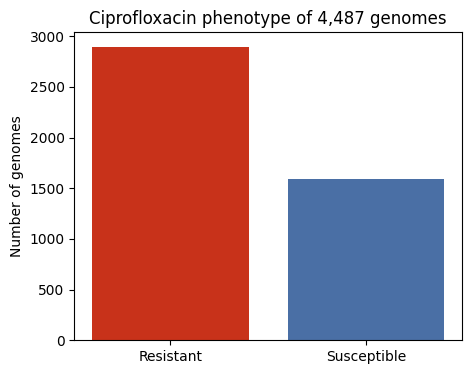

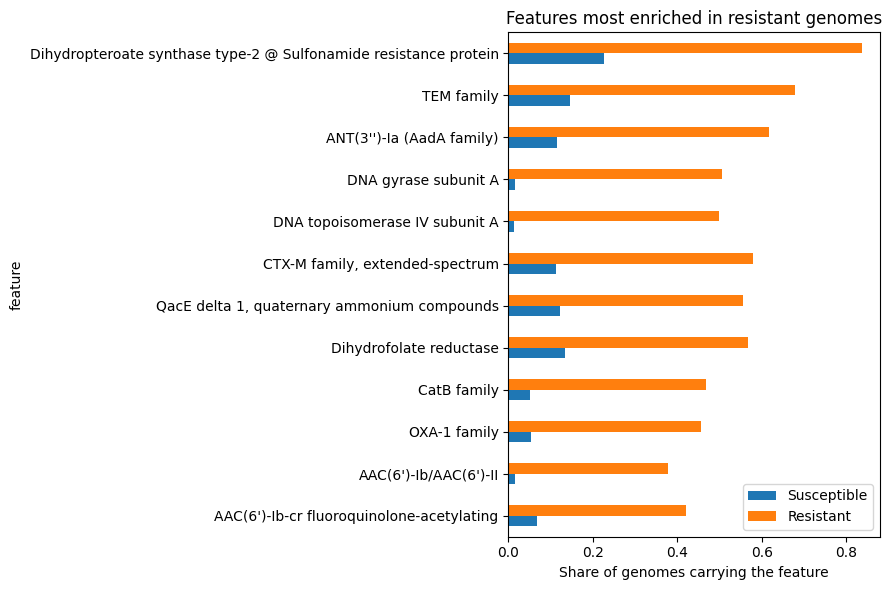

In [136]:
import matplotlib.pyplot as plt

counts = y.map({1: "Resistant", 0: "Susceptible"}).value_counts()
plt.figure(figsize=(5, 4))
plt.bar(counts.index, counts.values, color=["#c8321a", "#4a6fa5"])
plt.ylabel("Number of genomes")
plt.title(f"Ciprofloxacin phenotype of {len(y):,} genomes")
plt.show()

prev = X.groupby(y).mean().T
prev.columns = ["Susceptible", "Resistant"]
prev["diff"] = prev["Resistant"] - prev["Susceptible"]
top = prev.sort_values("diff").tail(12)
top[["Susceptible", "Resistant"]].plot.barh(figsize=(9, 6))
plt.xlabel("Share of genomes carrying the feature")
plt.title("Features most enriched in resistant genomes")
plt.tight_layout()
plt.show()

**Plot 1: class balance**

The classes are imbalanced. 2,894 of the 4,487 genomes (64.5%) are resistant
and 1,593 (35.5%) are susceptible. A model that always guesses "resistant"
would already be right about 65% of the time, so accuracy alone will not
tell us much. We also use precision, recall, F1 and AUC. Both groups are
large, so there are plenty of susceptible examples to learn from.

**Plot 2: features most enriched in resistant genomes**

This plot shows the features with the biggest gap between resistant and
susceptible genomes. The gyrA and parC hits matter most for ciprofloxacin:
about half of resistant genomes carry each of them (51% and 50%), against
only about 1 to 2% of susceptible genomes. AAC(6')-Ib-cr is also enriched
(42% vs 7%).

These hits are in only about half of resistant genomes, so many resistant
genomes must resist the drug in other ways.

The biggest gaps in size come from genes for other drugs, like the
sulfonamide gene (84% vs 23%) and CTX-M (58% vs 11%). They probably appear
because they travel together on the same plasmids or strains, so they follow
resistance without causing it.

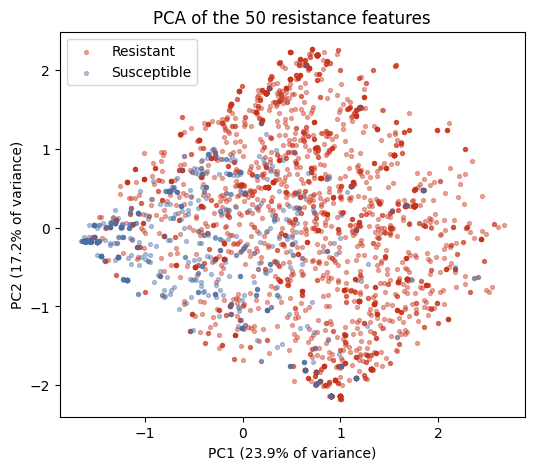

In [137]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

plt.figure(figsize=(6, 5))
for label, name, col in [(1, "Resistant", "#c8321a"), (0, "Susceptible", "#4a6fa5")]:
    mask = (y == label).values
    plt.scatter(pcs[mask, 0], pcs[mask, 1], s=8, alpha=0.4, c=col, label=name)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("PCA of the 50 resistance features")
plt.legend()
plt.show()

**Plot 3: PCA**

Resistant and susceptible genomes overlap, but they do not sit in the same
places. PC1 follows how many resistance genes a genome carries (correlation
0.97 between PC1 and the gene count): few on the left, many on the right,
and genomes on the far left are mostly susceptible. There is no clean split
in the middle of the plot, so no single feature separates the two groups.

In [138]:
import numpy as np
print(np.corrcoef(pcs[:, 0], X.sum(axis=1))[0, 1])

0.9714316701141188


# Stage 5: Core analysis

For each of the 54 features we ran Fisher's exact test (resistant vs
susceptible) and corrected the p-values for testing many features at once
with FDR (Benjamini-Hochberg). The odds ratio shows how much more likely
resistance is when a feature is present.

In [139]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

rows = []
for f in X.columns:
    a = ((X[f] == 1) & (y == 1)).sum()
    b = ((X[f] == 1) & (y == 0)).sum()
    c = ((X[f] == 0) & (y == 1)).sum()
    d = ((X[f] == 0) & (y == 0)).sum()
    _, p = fisher_exact([[a, b], [c, d]])
    odds = ((a + 0.5) * (d + 0.5)) / ((b + 0.5) * (c + 0.5))
    rows.append({"feature": f, "in_resistant": a, "in_susceptible": b,
                 "odds_ratio": odds, "p_value": p})

res = pd.DataFrame(rows)
res["p_adj"] = multipletests(res["p_value"], method="fdr_bh")[1]
res["significant"] = res["p_adj"] < 0.05
res = res.sort_values("p_adj")
res.to_csv(DATA_DIR + "/stage5_results.csv", index=False)
print(res.head(15).to_string(float_format=lambda v: f"{v:.3g}"))
print(res["significant"].sum(), "of", len(res), "features significant at FDR 5%")

                                                             feature  in_resistant  in_susceptible  odds_ratio   p_value     p_adj  significant
21  Dihydropteroate synthase type-2 @ Sulfonamide resistance protein          2426             362        17.6         0         0         True
18                                    DNA topoisomerase IV subunit A          1441              20        76.1 1.75e-313 4.73e-312         True
17                                              DNA gyrase subunit A          1464              26        60.6 1.42e-311 2.55e-310         True
46                                                        TEM family          1965             234        12.3 7.85e-275 1.06e-273         True
4                                          ANT(3'')-Ia (AadA family)          1789             185        12.3  2.1e-254 2.27e-253         True
11                                   CTX-M family, extended-spectrum          1679             181        10.8 2.95e-224 2.65e-223      

51 features above 1, 3 below 1


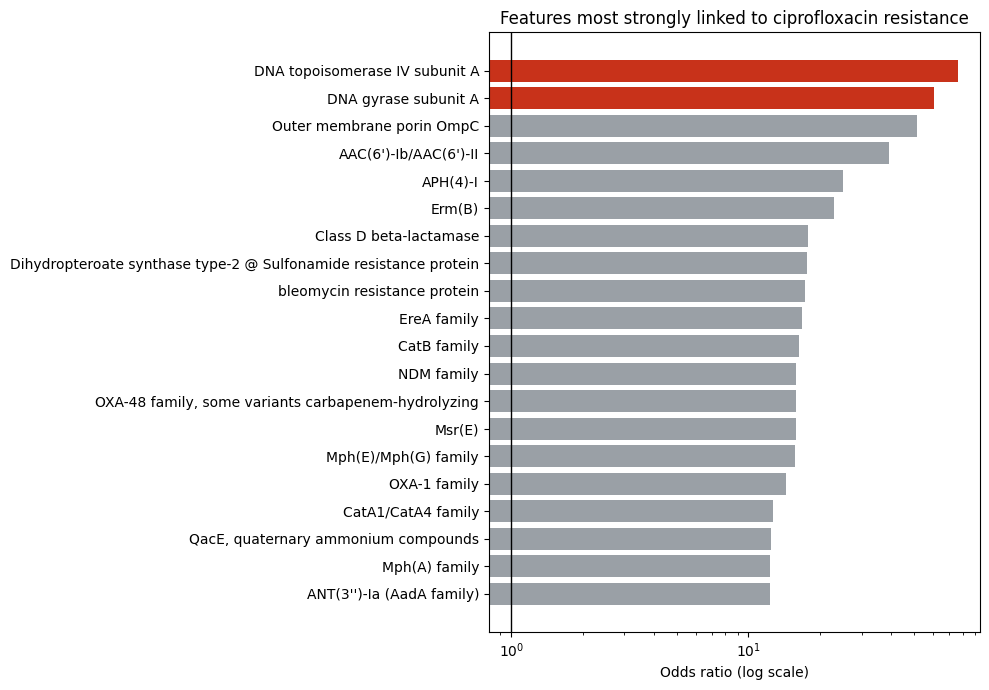

In [140]:
print((res["odds_ratio"] > 1).sum(), "features above 1,",
      (res["odds_ratio"] < 1).sum(), "below 1")

plot = res.sort_values("odds_ratio").tail(20)
cipro = ["DNA gyrase subunit A", "DNA topoisomerase IV subunit A",
         "AAC(6')-Ib-cr fluoroquinolone-acetylating",
         "Quinolone resistance protein QnrB10"]
colors = ["#c8321a" if f in cipro else "#9aa0a6" for f in plot["feature"]]

plt.figure(figsize=(10, 7))
plt.barh(plot["feature"], plot["odds_ratio"], color=colors)
plt.xscale("log")
plt.axvline(1, color="black", linewidth=1)
plt.xlabel("Odds ratio (log scale)")
plt.title("Features most strongly linked to ciprofloxacin resistance")
plt.tight_layout()
plt.show()

In [141]:
print(res[res["odds_ratio"] < 1][["feature", "odds_ratio", "p_adj"]].round(3).to_string())

                         feature  odds_ratio  p_adj
28                    LEN family       0.054    0.0
33  OKP-B family, broad-spectrum       0.105    0.0
37     Outer membrane porin OmpF       0.198    0.0


In [142]:
names = lab.set_index("genome_id")["genome_name"]
for f in ["LEN family", "OKP-B family, broad-spectrum"]:
    ids = X.index[X[f] == 1]
    print(f)
    print(names[ids].str.split().str[:2].str.join(" ").value_counts().head())

LEN family
genome_name
Klebsiella pneumoniae    80
Name: count, dtype: int64
OKP-B family, broad-spectrum
genome_name
Klebsiella pneumoniae    57
Name: count, dtype: int64


**Stage 5: results**

Fisher's exact test was run on all 54 features, with FDR correction. 52 came
out significant (adjusted p < 0.05). That is mostly because the sample is
large (4,487 genomes), so I ranked the features by odds ratio to see which
links are strongest. The full table is saved as stage5_results.csv.

The two ciprofloxacin features at the top are topoisomerase IV A (parC) and
gyrase A (gyrA), with odds ratios of about 76 and 61: resistance is far more
likely when either one is present. The OmpC porin is next (about 51), then
AAC(6')-Ib/AAC(6')-II (about 39). A porin is a channel through the cell
wall, so the OmpC hit could point to less drug getting in. I look at this in
Stage 6.

The plasmid genes aimed at ciprofloxacin are weaker: AAC(6')-Ib-cr has an
odds ratio of about 10 and QnrB10 about 8. Most of the other top features act
on different drugs, such as macrolides (Erm(B)), aminoglycosides (APH(4)-I)
and beta-lactams. They are probably markers of multidrug-resistant strains
that also carry the ciprofloxacin changes, not causes of ciprofloxacin
resistance.

Only three features had an odds ratio below 1, meaning they were more common
in susceptible genomes: the LEN family (0.05), the OKP-B family (0.11) and
the outer membrane porin OmpF (0.20). All three were significant after FDR
correction (adjusted p < 0.001).

Caution: the test treats every genome as independent, but genomes from the
same strain are related, which makes the p-values look stronger than they
are. Odds ratios for rare genes also rest on small counts.

# Stage 6: Biological interpretation

We used a literature comparison. We grouped the 54 features by how they could
affect ciprofloxacin, compared the groups, and checked our results against
published work.

In [143]:
def group(f):
    name = f.lower()
    if "gyrase" in name or "topoisomerase" in name:
        return "Target site (gyrA/parC)"
    if "qnr" in name or "aac(6')-ib-cr" in name:
        return "Plasmid quinolone resistance (qnr, aac(6')-Ib-cr)"
    if "porin" in name:
        return "Drug entry (porin)"
    if "efflux" in name:
        return "Efflux pumps"
    return "Genes for other drug classes"

res["mechanism"] = res["feature"].apply(group)
print(res.groupby("mechanism")["odds_ratio"].agg(["count", "median", "max"]).round(1))

both = ((X["DNA gyrase subunit A"] == 1) &
        (X["DNA topoisomerase IV subunit A"] == 1)).sum()
print(both, "genomes have both a gyrA and a parC hit")

                                                   count  median   max
mechanism                                                             
Drug entry (porin)                                     2    25.7  51.3
Efflux pumps                                           2     2.5   2.6
Genes for other drug classes                          45     9.3  39.1
Plasmid quinolone resistance (qnr, aac(6')-Ib-cr)      3     7.8   9.8
Target site (gyrA/parC)                                2    68.3  76.1
1460 genomes have both a gyrA and a parC hit


**Target site (gyrA and parC).** Ciprofloxacin works by blocking two
enzymes, DNA gyrase and topoisomerase IV. Changes in the gyrA and parC genes
stop the drug from binding. These had the strongest links to resistance in my
data (odds ratios 61 and 76, which means genomes with them were many times
more likely to be resistant). A 2025 preprint on 12,167 genomes found the
same. My data only says a hit was found, not which mutation.

**Plasmid genes (AAC(6')-Ib-cr and QnrB10).** Qnr proteins protect the
enzymes from the drug, and AAC(6')-Ib-cr modifies the drug. Published work
says each one gives only a small rise in resistance alone, which fits their
weaker odds ratios (about 10 and 8).

**Drug entry (OmpC porin).** Porins are channels that let the drug into the
cell. The OmpC hit had an odds ratio of about 51, but Ismah et al. (2018)
found that porin changes only raise resistance a little (about 4 fold for
OmpF). So it probably appears together with other changes.

**Genes for other drugs.** CTX-M, TEM and similar genes do not act on
ciprofloxacin. They are most likely passengers carried by multidrug-resistant
strains. This fits the PCA, where the first axis followed gene count
(correlation 0.97), and Stage 7, where counting genes alone gave 88%
accuracy.

**Linked to susceptibility.** LEN, OKP-B and OmpF were more common in
susceptible genomes. LEN and OKP-B are usually found in related Klebsiella
species, but these genomes are all labelled K. pneumoniae, so we could not
explain this. We leave all three unexplained.

**Answer to the question:** gyrA and parC are the strongest and most direct
link to ciprofloxacin resistance, but only about half of resistant genomes
carry one. Plasmid genes add smaller effects, and the other-drug genes are
mostly passengers.

**References**
- Ciprofloxacin resistance in Klebsiella pneumoniae: phenotype prediction
  from genotype and global distribution of resistance determinants. bioRxiv, 2025. https://www.biorxiv.org/content/10.1101/2025.09.24.678318
- Ismah et al. 2018, fluoroquinolone nonsusceptibility in Klebsiella
  pneumoniae. Antimicrobial Agents and Chemotherapy.
  https://pmc.ncbi.nlm.nih.gov/articles/PMC5826109
- Review of plasmid-mediated quinolone resistance (2006).
  https://www.um.es/biomybiotec/web/Seminarios/2008/papers/A_Pascual_Lancet_Infect_Dis_Rev_qnr_2006.pdf
- Study of Hungarian bloodstream isolates (ST11, ST307), Frontiers in
  Microbiology, 2019.
  https://www.frontiersin.org/articles/10.3389/fmicb.2019.00157/pdf

#Stage 7: machine learning

We split the 4,487 genomes 80/20 into training and test sets (keeping the
resistant/susceptible ratio), compared three simple baselines with logistic
regression and a random forest, and judged them on the test set.

The always-resistant baseline gets 64.5% accuracy without learning anything,
so that is the number to beat. The rule "gyrA or parC hit" is right 98% of
the time when it says resistant, but it finds only half of the resistant
genomes (recall 0.50). A simple rule that calls a genome resistant if it
carries 10 or more resistance genes does surprisingly well (88.0% accuracy,
AUC 0.94).

Both real models do better: logistic regression reached 91.9% accuracy and
AUC 0.96, and the random forest 92.7% and AUC 0.96, with recall of 0.94 to
0.95. But the gain over the gene-count rule is small (about 4 to 5 points of
accuracy). Most of what the models learn seems to be how many resistance
genes a genome carries, which fits the PCA, where PC1 followed gene count.
So they mostly recognise multidrug-resistant strains, not ciprofloxacin
resistance specifically. The two models are very close, so I cannot say the
random forest is better.

In [144]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, balanced_accuracy_score)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

def scores(name, y_true, y_pred, y_score):
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred),
            "auc": roc_auc_score(y_true, y_score)}

results = []

pred = np.ones(len(y_test), dtype=int)
results.append(scores("Baseline: always resistant", y_test, pred, pred))

rule = ((X_test["DNA gyrase subunit A"] == 1) |
        (X_test["DNA topoisomerase IV subunit A"] == 1)).astype(int)
results.append(scores("Baseline: gyrA or parC hit", y_test, rule, rule))

count_train = X_train.sum(axis=1)
count_test = X_test.sum(axis=1)
best_k = max(range(1, int(count_train.max()) + 1),
             key=lambda k: balanced_accuracy_score(y_train, (count_train >= k).astype(int)))
pred = (count_test >= best_k).astype(int)
results.append(scores(f"Baseline: {best_k}+ resistance genes", y_test, pred, count_test))

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
results.append(scores("Logistic regression", y_test, logreg.predict(X_test),
                      logreg.predict_proba(X_test)[:, 1]))

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
results.append(scores("Random forest", y_test, rf.predict(X_test),
                      rf.predict_proba(X_test)[:, 1]))

print(pd.DataFrame(results).round(3).to_string(index=False))

                         model  accuracy  precision  recall    f1   auc
    Baseline: always resistant     0.645      0.645   1.000 0.784 0.500
    Baseline: gyrA or parC hit     0.673      0.977   0.504 0.665 0.741
Baseline: 10+ resistance genes     0.880      0.911   0.902 0.906 0.936
           Logistic regression     0.919      0.936   0.938 0.937 0.959
                 Random forest     0.927      0.937   0.950 0.943 0.959


In [145]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf.predict(X_test))
print(pd.DataFrame(cm, index=["truly susceptible", "truly resistant"],
                   columns=["predicted susceptible", "predicted resistant"]))

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10).round(3))

coef = pd.Series(logreg.coef_[0], index=X.columns).sort_values(ascending=False)
print(coef.head(8).round(2))
print(coef.tail(5).round(2))

                   predicted susceptible  predicted resistant
truly susceptible                    282                   37
truly resistant                       29                  550
feature
Dihydropteroate synthase type-2 @ Sulfonamide resistance protein    0.115
DNA gyrase subunit A                                                0.080
TEM family                                                          0.078
DNA topoisomerase IV subunit A                                      0.066
ANT(3'')-Ia (AadA family)                                           0.062
CTX-M family, extended-spectrum                                     0.061
AAC(6')-Ib/AAC(6')-II                                               0.053
CatB family                                                         0.045
KPC family, carbapenem-hydrolyzing                                  0.043
Quinolone resistance protein QnrB10                                 0.039
dtype: float64
feature
Pentapeptide repeat protein QnrB family    

**Errors (random forest, 898 test genomes).** It found 550 of the 579
resistant genomes and missed 29 (5%). It wrongly called 37 of the 319
susceptible genomes resistant (12%). Missing a resistant genome is the worse
mistake, because a patient could get a drug that will not work.

**What the models use.** gyrA and parC were among the most important
features, but six of the top 10 were genes for other drugs (sulfonamide, TEM,
ANT(3'')-Ia, CTX-M, CatB and KPC). So the models are largely recognising
multidrug-resistant strains in general. A rule of "10 or more resistance
genes" already scored 88%, and the models added only 4 to 5 points.

In [147]:
import re
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

target = [c for c in X.columns if re.search("gyrase|topoisomerase", c, re.I)]
plasmid = [c for c in X.columns if re.search("qnr|quinolone|pentapeptide|ib-cr", c, re.I)]
print("target-site:", target)
print("plasmid:", plasmid)

sets = {
    "All features": list(X.columns),
    "Target-site only": target,
    "Target-site + plasmid": target + plasmid,
    "Without these features": [c for c in X.columns if c not in target + plasmid],
}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

rows = []
for set_name, cols in sets.items():
    models = [
        ("Logistic regression", LogisticRegression(max_iter=1000)),
        ("Random forest", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    ]
    for model_name, model in models:
        model.fit(X_train[cols], y_train)
        pred = model.predict(X_test[cols])
        prob = model.predict_proba(X_test[cols])[:, 1]
        rows.append({
            "features": set_name,
            "n_features": len(cols),
            "model": model_name,
            "accuracy": accuracy_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "auc": roc_auc_score(y_test, prob),
        })

ablation = pd.DataFrame(rows).round(3)
print(ablation.to_string(index=False))
ablation.to_csv(DATA_DIR + "/ablation_results.csv", index=False)

target-site: ['DNA gyrase subunit A', 'DNA topoisomerase IV subunit A']
plasmid: ["AAC(6')-Ib-cr fluoroquinolone-acetylating", 'Pentapeptide repeat protein QnrB family', 'Quinolone resistance protein QnrB10']
              features  n_features               model  accuracy  recall    f1   auc
          All features          54 Logistic regression     0.919   0.938 0.937 0.959
          All features          54       Random forest     0.927   0.950 0.943 0.959
      Target-site only           2 Logistic regression     0.673   0.504 0.665 0.742
      Target-site only           2       Random forest     0.673   0.504 0.665 0.742
 Target-site + plasmid           5 Logistic regression     0.864   0.858 0.891 0.900
 Target-site + plasmid           5       Random forest     0.864   0.858 0.891 0.898
Without these features          49 Logistic regression     0.898   0.915 0.920 0.945
Without these features          49       Random forest     0.901   0.921 0.923 0.947


## Ablation: do the ciprofloxacin genes matter?

I trained the models again on smaller sets of features, using the same split.

| Features | Number | Accuracy (random forest) |
|---|---|---|
| All features | 54 | 0.927 |
| gyrA and parC only | 2 | 0.673 |
| gyrA, parC and the 3 plasmid genes | 5 | 0.864 |
| Everything except those 5 | 49 | 0.901 |

- gyrA and parC alone are not enough. They found only half of the resistant
  genomes.
- Adding the three plasmid genes raised accuracy from 0.673 to 0.864, which
  supports the second part of my hypothesis.
- But the other 49 genes alone still scored about 0.90, so most of the signal
  is the overall resistance gene count.
- Caution: the other genes can stand in for the removed ones, because
  plasmids carry several resistance genes together. This is also one test
  split, so small differences are not meaningful. Logistic regression gave
  similar results.

# Stage 8: Conclusions
## Findings

**Objective 1 (how common):** We used 4,487 genomes (2,894 resistant and 1,593
susceptible) and 54 features. 51 of the 54 were more common in resistant
genomes. gyrA and parC hits were found in only about half of the resistant
genomes, so resistance often happens without them.

**Objective 2 (association):** [N] of the 54 features were significantly
linked to resistance after correcting for testing many features at once. The
strongest were gyrA and parC (odds ratios 61 and 76), then OmpC, then the
plasmid genes AAC(6')-Ib-cr and QnrB10. Many genes for other drugs were also
linked, but they most likely just travel with resistance.

**Objective 3 (classifier):** The random forest got 92.7% accuracy against
64.5% for always guessing resistant. But a simple rule of "10 or more
resistance genes" already got 88%, so the models added only 4 to 5 points.
The ablation showed that most of what they learn is the overall resistance
gene count.

## Hypothesis

Partly supported. gyrA and parC were the strongest single markers but found
only half of the resistant genomes. Plasmid genes did improve accuracy (0.673
to 0.864 when added to gyrA and parC).

## Limitations

- Related genomes in both the training and test sets probably make the scores
  look better than they are.
- Genes for other drugs travel with resistance, so we cannot tell cause from
  company.
- 1,640 genomes with no annotation had to be removed, and differences between
  studies may still affect the rest.
- We only know a gyrA or parC hit was found, not which mutation.
- Labels come from many studies, and we did not check where the genomes came
  from. Public data is mostly from outside Africa, so the results may not hold
  for Kenyan strains.
- About 65% of genomes were resistant, so accuracy alone is generous.

## Future steps

- Split by lineage so no clone is in both the training and test sets.
- Get the exact gyrA and parC mutations from the sequences.
- Test on a separate dataset, ideally including Kenyan genomes.